# Model interpretation


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, make_scorer
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


## Train/test split
Load the cleaned dataset and split into train and test sets using the same parameters as 04_models.


In [2]:
path = os.path.join('..', 'data', 'cleaned_salary_data.csv')
df = pd.read_csv(path)

X = df.drop(columns=['Salary'])
y = df['Salary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

cat_cols = ['Country', 'Education', 'Role', 'RemoteWork', 'OrgSize']
num_cols = ['Experience_Years', 'Work_Experience_Years']

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('num', StandardScaler(), num_cols)
])

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")


X_train: (13563, 7), X_test: (3391, 7)


My observation: 


## Hyperparameter tuning
Tune Ridge alpha and Random Forest parameters using 5-fold cross-validation on the training set.


In [3]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# dollar mae scorer for log-scale target
def dollar_mae_scorer(y_true_log, y_pred_log):
    return -mean_absolute_error(np.exp(y_true_log), np.exp(y_pred_log))

dollar_scorer = make_scorer(dollar_mae_scorer, greater_is_better=True)

# ridge tuning
ridge_pipe = Pipeline([('prep', preprocessor), ('reg', Ridge())])
ridge_search = GridSearchCV(
    ridge_pipe,
    {'reg__alpha': [0.1, 1, 3, 10, 30, 100]},
    cv=kf,
    scoring=dollar_scorer
)
ridge_search.fit(X_train, np.log(y_train))
best_ridge_alpha = ridge_search.best_params_['reg__alpha']
print(f"Best Ridge alpha: {best_ridge_alpha}")

# random forest tuning
rf_pipe = Pipeline([
    ('prep', preprocessor),
    ('reg', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])
rf_param_dist = {
    'reg__min_samples_leaf': [5, 10, 20, 30],
    'reg__max_features': ['sqrt', 0.5, 1.0]
}
rf_search = RandomizedSearchCV(
    rf_pipe,
    rf_param_dist,
    n_iter=12,
    cv=kf,
    scoring=dollar_scorer,
    random_state=42,
    n_jobs=-1
)
rf_search.fit(X_train, np.log(y_train))
best_rf_params = rf_search.best_params_
print(f"Best RF params: {best_rf_params}")


Best Ridge alpha: 0.1


Best RF params: {'reg__min_samples_leaf': 5, 'reg__max_features': 0.5}


My observation: 


## Cross-validation comparison
Evaluate all six candidate models on the training set using the same 5-fold cross-validation split.


In [4]:
models = {
    'Ridge default': Ridge(alpha=1.0),
    'Ridge tuned': Ridge(alpha=best_ridge_alpha),
    'RF default': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'RF tuned': RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=best_rf_params['reg__min_samples_leaf'],
        max_features=best_rf_params['reg__max_features'],
        random_state=42,
        n_jobs=-1
    ),
    'HistGB default': HistGradientBoostingRegressor(random_state=42),
    'HistGB tuned': HistGradientBoostingRegressor(
        learning_rate=0.15,
        max_iter=100,
        max_leaf_nodes=15,
        min_samples_leaf=50,
        l2_regularization=1.0,
        random_state=42
    )
}

cv_rows = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('reg', model)])
    fold_maes = []
    for tr_idx, val_idx in kf.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        pipe.fit(X_tr, np.log(y_tr))
        preds = np.exp(pipe.predict(X_val))
        fold_maes.append(mean_absolute_error(y_val, preds))
    cv_rows.append({
        'Model': name,
        'CV MAE Mean ($)': np.mean(fold_maes),
        'CV MAE Std ($)': np.std(fold_maes)
    })

df_cv = pd.DataFrame(cv_rows)
display(df_cv)

best_model_name = df_cv.sort_values('CV MAE Mean ($)').iloc[0]['Model']
print(f"Best model by CV: {best_model_name}")


,Model,CV MAE Mean ($),CV MAE Std ($)
0,Ridge default,"29,089.6739",750.4810
1,Ridge tuned,"29,087.6520",751.0050
2,RF default,"29,193.0625",608.6316
3,RF tuned,"28,461.9362",617.5056
4,HistGB default,"27,243.1701",543.7846
5,HistGB tuned,"27,251.0265",467.3582


Best model by CV: HistGB default


My observation: 


## Test set evaluation
Fit the best model selected by cross-validation on the full training set and evaluate on the test set once.


In [5]:
best_model = Pipeline([('prep', preprocessor), ('reg', models[best_model_name])])
best_model.fit(X_train, np.log(y_train))
y_pred = np.exp(best_model.predict(X_test))

test_results = pd.DataFrame([{
    'Model': best_model_name,
    'MAE ($)': mean_absolute_error(y_test, y_pred),
    'RMSE ($)': root_mean_squared_error(y_test, y_pred),
    'R-squared': r2_score(y_test, y_pred)
}])
display(test_results)


,Model,MAE ($),RMSE ($),R-squared
0,HistGB default,"26,476.3807","40,093.5106",0.5712


My observation: 


## Per-country error
Compute prediction error metrics across focus countries on the test set.


In [6]:
countries = [
    'India', 'Brazil', 'Poland', 'Germany',
    'United Kingdom of Great Britain and Northern Ireland',
    'United States of America'
]

test_df = X_test.copy()
test_df['actual'] = y_test
test_df['pred'] = y_pred

country_rows = []
for c in countries:
    sub = test_df[test_df['Country'] == c]
    act = sub['actual']
    pred = sub['pred']
    country_rows.append({
        'Country': c,
        'Test row count': len(sub),
        'Median actual salary ($)': act.median(),
        'Std actual salary ($)': act.std(),
        'MAE ($)': mean_absolute_error(act, pred),
        'MdAPE (%)': np.median(np.abs((act - pred) / act)) * 100,
        'Mean signed error ($)': np.mean(pred - act)
    })

df_country = pd.DataFrame(country_rows)
display(df_country)


,Country,Test row count,Median actual salary ($),Std actual salary ($),MAE ($),MdAPE (%),Mean signed error ($)
0,India,102,"34,872.0000","40,342.9115","19,382.4864",33.9028,"-8,272.1179"
1,Brazil,85,"38,228.0000","34,026.4062","20,387.3679",37.0297,"-8,049.3317"
2,Poland,73,"60,000.0000","29,482.2945","16,880.0972",24.3834,"-1,600.6480"
3,Germany,345,"87,011.0000","39,475.7196","21,502.8308",17.5981,"-6,232.7471"
4,United Kingdom of Great Britain and Northern I...,235,"91,147.0000","52,340.2234","29,686.9790",21.7337,"-5,885.1328"
5,United States of America,826,"150,000.0000","64,082.7233","39,667.5838",21.5600,"-7,037.8628"


My observation: 


## Permutation importance
Compute permutation feature importance on the test set using the original input columns. Importance values are in log-salary units.


,Feature,Importance Mean,Importance Std
0,Country,0.2641,0.0041
1,Work_Experience_Years,0.0595,0.0017
2,Role,0.0195,0.0014
3,OrgSize,0.0147,0.0009
4,RemoteWork,0.0131,0.0012
5,Experience_Years,0.0108,0.0015
6,Education,0.0068,0.0007


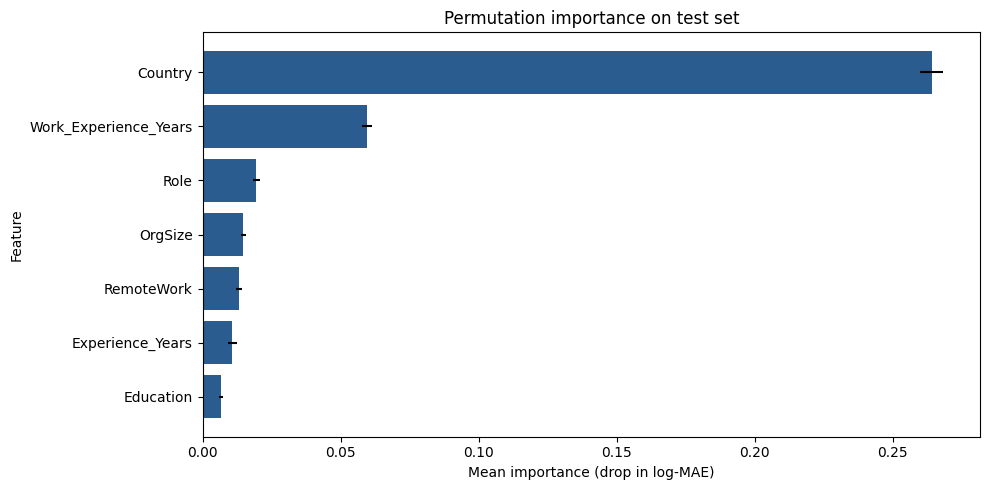

In [7]:
perm = permutation_importance(
    best_model, X_test, np.log(y_test),
    n_repeats=10, random_state=42,
    scoring='neg_mean_absolute_error'
)

df_perm = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance Mean': perm.importances_mean,
    'Importance Std': perm.importances_std
}).sort_values('Importance Mean', ascending=True)

display(df_perm.sort_values('Importance Mean', ascending=False).reset_index(drop=True))

plt.figure(figsize=(10, 5))
plt.barh(df_perm['Feature'], df_perm['Importance Mean'], xerr=df_perm['Importance Std'], color='#2b5c8f')
plt.xlabel('Mean importance (drop in log-MAE)')
plt.ylabel('Feature')
plt.title('Permutation importance on test set')
plt.tight_layout()
plt.show()


My observation: 


## Residual analysis
Plot predicted versus actual values and residuals versus predicted values on the test set. Residual is defined as actual minus predicted.


Mean residual: 6,507.74
Mean residual for actual salary > $200,000 (n=222): 94,760.01
Mean residual for actual salary < $30,000 (n=311): -17,833.13


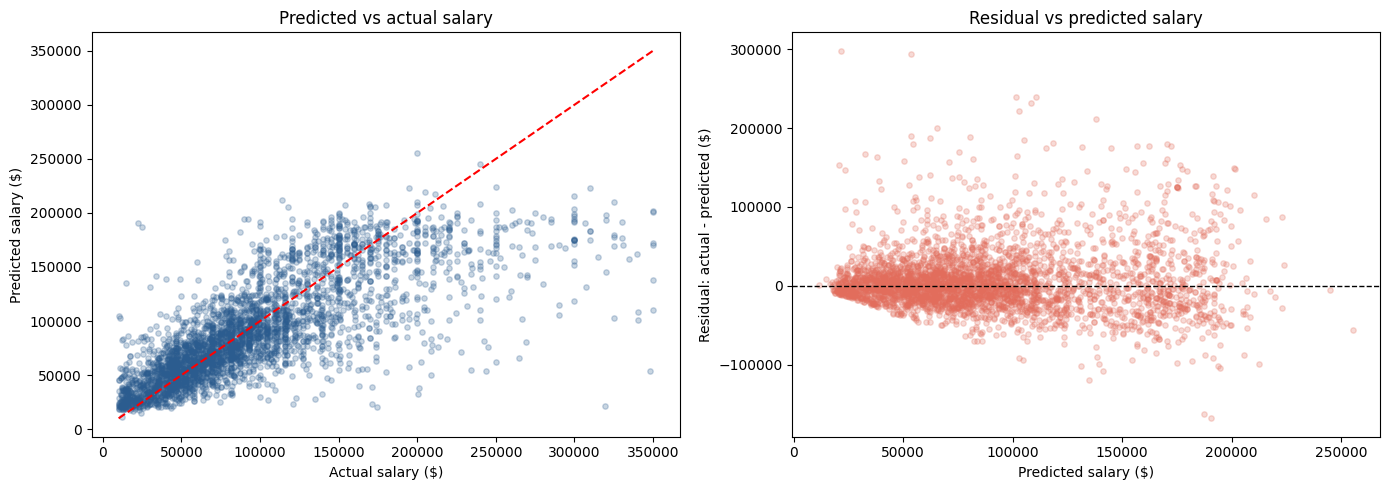

In [8]:
residuals = y_test - y_pred

mean_res = np.mean(residuals)
mean_res_high = np.mean(residuals[y_test > 200000])
count_high = np.sum(y_test > 200000)
mean_res_low = np.mean(residuals[y_test < 30000])
count_low = np.sum(y_test < 30000)

print(f"Mean residual: {mean_res:,.2f}")
print(f"Mean residual for actual salary > $200,000 (n={count_high}): {mean_res_high:,.2f}")
print(f"Mean residual for actual salary < $30,000 (n={count_low}): {mean_res_low:,.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# predicted vs actual
axes[0].scatter(y_test, y_pred, alpha=0.25, s=15, color='#2b5c8f')
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5)
axes[0].set_xlabel('Actual salary ($)')
axes[0].set_ylabel('Predicted salary ($)')
axes[0].set_title('Predicted vs actual salary')

# residual vs predicted
axes[1].scatter(y_pred, residuals, alpha=0.25, s=15, color='#e26d5c')
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_xlabel('Predicted salary ($)')
axes[1].set_ylabel('Residual: actual - predicted ($)')
axes[1].set_title('Residual vs predicted salary')

plt.tight_layout()
plt.show()


My observation: 
